In [21]:
import sys
print(sys.executable)

c:\Users\ASUS\anaconda3\python.exe


In [22]:
!pip install fastapi "uvicorn[standard]" python-multipart jinja2 python-dotenv pydantic langchain langchain-core langchain-community langchain-text-splitters langgraph langgraph-checkpoint-sqlite tavily-python pypdf python-docx langchain-groq langchain-huggingface sentence-transformers langchain-qdrant qdrant-client

Defaulting to user installation because normal site-packages is not writeable


In [23]:
import sys
!{sys.executable} -m pip install fastapi "uvicorn[standard]" python-multipart jinja2 python-dotenv pydantic

In [24]:
import sys
!{sys.executable} -m pip install langchain langchain-core langchain-community langchain-text-splitters langgraph langchain-groq tavily-python pypdf python-docx

In [25]:
import sys
!{sys.executable} -m pip install langchain-huggingface sentence-transformers langchain-qdrant qdrant-client

In [26]:
%pip install --upgrade typing-extensions

Note: you may need to restart the kernel to use updated packages.


In [27]:
import sys
import typing_extensions

print("Python:", sys.executable)
print("typing_extensions:", typing_extensions.__file__)
print("TypeForm available:", hasattr(typing_extensions, "TypeForm"))

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_qdrant import QdrantVectorStore
from qdrant_client import QdrantClient
from qdrant_client.http.models import Distance, VectorParams
from langgraph.graph import StateGraph, START, END

print("All imports succeeded")

Python: c:\Users\ASUS\anaconda3\python.exe
typing_extensions: c:\Users\ASUS\anaconda3\Lib\site-packages\typing_extensions.py
TypeForm available: True
All imports succeeded


In [28]:
from typing import List, TypedDict, Literal
from pydantic import BaseModel, Field

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_qdrant import QdrantVectorStore
from qdrant_client import QdrantClient
from qdrant_client.http.models import Distance, VectorParams

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

load_dotenv()

True

In [29]:
docs = (
    PyPDFLoader("./documents/RunbookPilot_Company_Profile.pdf").load()
    + PyPDFLoader("./documents/RunbookPilot_Comprehensive_Employee_Handbook.pdf").load()
    + PyPDFLoader("./documents/RunbookPilot_Products_Pricing_Catalog.pdf").load()
)

In [30]:
chunks = RecursiveCharacterTextSplitter(
    chunk_size=600, chunk_overlap=150
).split_documents(docs)

In [31]:
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
vector_store = QdrantVectorStore.from_documents(
    documents=chunks,
    embedding=embeddings,
    location=":memory:",
    collection_name="ashish_ai_collection",
)
retriever = vector_store.as_retriever(search_kwargs={"k": 4})

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [124]:
from langchain_groq import ChatGroq

# Use an active, supported model ID on Groq
llm = ChatGroq(
    model="openai/gpt-oss-20b",  # or "openai/gpt-oss-120b"
    temperature=0
)

In [125]:
# --------------------------------------------------
# Graph State
# --------------------------------------------------
class State(TypedDict):
    question: str
    need_retrieval: bool

    docs: List[Document]

    answer: str

In [126]:
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )

decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)


# IMPORTANT: no `.content` for structured output
should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

def decide_retrieval(state: "State"):
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    return {"need_retrieval": decision.should_retrieve}

In [127]:
direct_generation_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "Answer the question using only your general knowledge.\n"
        "Do NOT assume access to external documents.\n"
        "If you are unsure or the answer requires specific sources, say:\n"
        "'I don't know based on my general knowledge.'"
    ),
    ("human", "{question}"),
])

def generate_direct(state: State):
    out = llm.invoke(
        direct_generation_prompt.format_messages(question=state["question"])
    )
    return {"answer": out.content}

In [128]:
def retrieve(state: State):
    return {"docs": retriever.invoke(state["question"])}

In [129]:
class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ...,
        description="True if the document helps answer the question, else False."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "You are judging document relevance.\n"
        "Return JSON that matches this schema:\n"
        "{{'is_relevant': boolean}}\n\n"
        "A document is relevant if it contains information useful for answering the question."
    ),
    ("human", "Question:\n{question}\n\nDocument:\n{document}"),
])

In [130]:
from langgraph.graph import StateGraph, START, END

# 1. Define the retrieval node function
def retrieve_node(state: State):
    retrieved_docs = retriever.invoke(state["question"])
    return {"docs": retrieved_docs}

# 2. Define the RAG generation node function
def generate_rag(state: State):
    context = "\n\n".join([doc.page_content for doc in state["docs"]])
    rag_prompt = f"Answer the question based only on this context:\n\n{context}\n\nQuestion: {state['question']}"
    out = llm.invoke(rag_prompt)
    return {"answer": out.content}

# 3. Initialize and build the StateGraph
g = StateGraph(State)

# Add all nodes
g.add_node("decide_retrieval", decide_retrieval)
g.add_node("generate_direct", generate_direct)
g.add_node("retrieve", retrieve_node)
g.add_node("generate_rag", generate_rag)

# Add entrypoint and edges
g.add_edge(START, "decide_retrieval")

g.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {
        "generate_direct": "generate_direct",
        "retrieve": "retrieve",
    },
)

g.add_edge("generate_direct", END)
g.add_edge("retrieve", "generate_rag")
g.add_edge("generate_rag", END)

# Compile the final application
app = g.compile()
print("Graph compiled successfully with all nodes defined!")

Graph compiled successfully with all nodes defined!


In [131]:
# Node 5: RAG Generation (Using Filtered Relevant Docs)
def generate_rag(state: State):
    context = "\n\n".join([doc.page_content for doc in state["relevant_docs"]])
    rag_prompt = f"Answer the question based only on this context:\n\n{context}\n\nQuestion: {state['question']}"
    out = llm.invoke(rag_prompt)
    return {"answer": out.content}

In [132]:
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    if state["need_retrieval"]:
        return "retrieve"
    return "generate_direct"

In [133]:
# New

class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ...,
        description="True if the document helps answer the question, else False."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging document relevance.\n"
            "Return JSON that matches this schema:\n"
            "{{'is_relevant': boolean}}\n\n"
            "A document is relevant if it contains information useful for answering the question."
        ),
        (
            "human",
            "Question:\n{question}\n\nDocument:\n{document}"
        ),
    ]
)

relevance_llm = llm.with_structured_output(RelevanceDecision)

def is_relevant(state: State):
    
    relevant_docs: List[Document] = []

    for doc in state["docs"]:
        decision: RelevanceDecision = relevance_llm.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content
            )
        )

        if decision.is_relevant:
            relevant_docs.append(doc)

    return {"relevant_docs": relevant_docs}



In [134]:
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    if state["need_retrieval"]:
        return "retrieve"
    return "generate_direct"

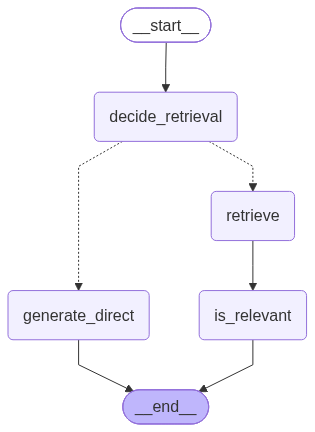

In [135]:
g = StateGraph(State)

# --------------------
# Nodes
# --------------------
g.add_node("decide_retrieval", decide_retrieval)
g.add_node("generate_direct", generate_direct)
g.add_node("retrieve", retrieve)
g.add_node("is_relevant", is_relevant) # New

# --------------------
# Edges
# --------------------
g.add_edge(START, "decide_retrieval")

g.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {
        "generate_direct": "generate_direct",
        "retrieve": "retrieve",
    },
)

g.add_edge("generate_direct", END)
g.add_edge("retrieve", "is_relevant") # New
g.add_edge("is_relevant", END) # New

app = g.compile()
app

In [136]:
result = app.invoke(
    {
        "question": "Who is the Founder of Starlink",
        "need_retrieval": False,
        "docs": [],
        "answer": "",
    }
)

print(result["answer"])

The founder of Starlink is Elon Musk.


In [102]:
result['need_retrieval']

False

In [103]:
for doc in result['docs']:
    print(doc.page_content)
    print("*"*100)

In [104]:
def inspect_retrieved_docs(result):
    # Check for either 'relevant_docs' or 'docs' in the result state
    docs = result.get('relevant_docs', result.get('docs', []))
    
    if not docs:
        print("No retrieved documents found in this result.")
        return
        
    for i, doc in enumerate(docs, 1):
        # PyPDFLoader page numbers are 0-indexed, so add 1 for the actual page number
        page_num = doc.metadata.get('page', 0) + 1
        source = doc.metadata.get('source', 'Unknown')
        
        print(f"--- Document Chunk {i} ---")
        print(f"📁 Source: {source} | 📄 Page: {page_num}")
        print(doc.page_content)
        print("*" * 100)

# How to use it after running your graph stream or invoke:
# inspect_retrieved_docs(result)

In [105]:
for doc in result['docs']:  # Use 'relevant_docs' if that is your state key
    # PyPDFLoader page numbers are 0-indexed, so add 1 for the actual page number
    page_num = doc.metadata.get('page', 0) + 1
    source = doc.metadata.get('source', 'Unknown')
    
    print(f"📁 Source: {source} | 📄 Page: {page_num}")
    print(doc.page_content)
    print("*" * 100)

In [106]:
print("Need Retrieval:", result.get('need_retrieval'))
print("Docs:", result.get('docs'))
print("Answer:", result.get('answer'))

Need Retrieval: False
Docs: []
Answer: The founder of Starlink is Elon Musk.


In [107]:
result['docs']

[]

In [108]:
for doc in result['docs']:
    print(doc.page_content)
    print("*"*100)

In [110]:
# Safely check if relevant_docs or docs exist in the result state
docs_to_print = result.get('relevant_docs', result.get('docs', []))

if not docs_to_print:
    print("No documents were retrieved for this query (Direct Generation used).")
else:
    for doc in docs_to_print:
        print(doc.page_content)
        print("*" * 100)

print("\nFinal Answer:")
print(result.get("answer"))

No documents were retrieved for this query (Direct Generation used).

Final Answer:
The founder of Starlink is Elon Musk.
